# Team information and work plan

| STT | Họ và tên | MSSV |
|---|---|---|
| 1 | Nguyễn Ngọc Cảnh | 23127161 |
| 2 | Lê Minh Đức | 23127351 |
| 3 | Thái Minh Khoa | 23127394 |

Nhóm phân chia sáu stage của pipeline thành ba phần. Mỗi thành viên phụ trách nghiên cứu phương pháp, triển khai, kiểm tra tính đúng và trình bày kết quả cho các stage được giao.

V0 là phiên bản C/C++ đơn luồng làm mốc so sánh. V1 chuyển toàn bộ sáu stage lên GPU bằng CUDA. V2 và V3 lần lượt bổ sung các tối ưu dựa trên kết quả profiling.

| Thành viên | Stage phụ trách | V0: Sequential | V1: Basic CUDA | V2 và V3: Optimized CUDA |
|---|---|---|---|---|
| Thái Minh Khoa | Stage 1: Preprocessing; Stage 2: Keypoint detection | Nghiên cứu, lựa chọn phương pháp và triển khai tuần tự hai stage đầu | Xây dựng CUDA kernels cho preprocessing và keypoint detection | Phân tích thời gian, đề xuất và triển khai tối ưu thuộc stage 1–2 khi được lựa chọn |
| Nguyễn Ngọc Cảnh | Stage 3: Description; Stage 4: Matching | Nghiên cứu, lựa chọn phương pháp và triển khai tuần tự descriptor và matching | Xây dựng CUDA kernels cho description và matching | Phân tích thời gian, đề xuất và triển khai tối ưu thuộc stage 3–4 khi được lựa chọn |
| Lê Minh Đức | Stage 5: Homography estimation; Stage 6: Warping and blending | Nghiên cứu, lựa chọn phương pháp và triển khai tuần tự hai stage cuối | Xây dựng CUDA kernels cho homography estimation, warping và blending | Phân tích thời gian, đề xuất và triển khai tối ưu thuộc stage 5–6 khi được lựa chọn |

**Kế hoạch dự kiến cho V2 và V3:** mỗi phiên bản bổ sung một ý tưởng tối ưu chính để đo riêng tác động. Thành viên phụ trách stage được chọn sẽ chủ trì triển khai; hai thành viên còn lại hỗ trợ kiểm tra và tích hợp. V3 kế thừa các tối ưu có hiệu quả của V2. Các phiên bản giữ cùng phương pháp và tham số để bảo đảm so sánh công bằng.

### Work plan
| Giai đoạn | Công việc và kết quả dự kiến | Người phụ trách | Mốc dự kiến |
|---|---|---|---|
| Chuẩn bị dữ liệu | Chụp ít nhất bốn cặp ảnh, gồm ba cặp điều kiện thông thường và một cặp khó; chuẩn hóa tỷ lệ 16:9 ở ba mức HD, Full HD và 4K | Khoa | 01/11 |
| Chuẩn bị notebook | Tạo bố cục báo cáo với đầy đủ các mục cần trình bày | Cảnh | 01/11 |
| Thiết lập repository | Tạo GitHub repository, tổ chức thư mục `src/` và cấp quyền cộng tác cho các thành viên | Đức | 01/11 |
| Nghiên cứu phương pháp | So sánh ưu, nhược điểm; lựa chọn phương pháp và tham số cho từng stage theo phân công | Cả nhóm | 04/11 |
| Xây dựng V0 | Triển khai các module, tích hợp đủ sáu stage và chạy pipeline tuần tự từ notebook | Cả nhóm | 07/11 |
| Hoàn thiện báo cáo giữa kỳ | Trình bày phương pháp, dữ liệu, kiểm tra tính đúng, panorama, thời gian từng stage, phân tích bottleneck và kế hoạch GPU | Cả nhóm | 07/11 |
| Xây dựng V1 | Chuyển đủ sáu stage lên GPU; đối chiếu kết quả với V0 và đo hiệu năng | Cả nhóm, theo stage phụ trách | Sau giữa kỳ |
| Xây dựng V2 | Chọn bottleneck từ profiling của V1, áp dụng một tối ưu chính và đánh giá tác động | Chủ trì bởi thành viên phụ trách stage được chọn; cả nhóm hỗ trợ | Sau V1 |
| Xây dựng V3 | Phân tích V2, bổ sung một tối ưu chính tiếp theo và đánh giá chất lượng, thời gian, speedup | Chủ trì bởi thành viên phụ trách stage được chọn; cả nhóm hỗ trợ | Sau V2 |
| Hoàn thiện bài nộp cuối kỳ | Tổng hợp so sánh các phiên bản; hoàn thiện notebook, mã nguồn, README, slides và video; kiểm tra khả năng chạy lại và đóng gói | Cả nhóm | Trước hạn nộp chính thức |

# Problem understanding

## Mô tả bài toán

Panorama image stitching là bài toán ghép các ảnh có vùng nhìn chồng lấp thành một ảnh toàn cảnh. Hai ảnh chụp cùng một cảnh từ các hướng khác nhau thường có sự khác biệt về vị trí, góc nhìn và độ sáng. Vì vậy, chương trình cần xác định những vùng tương ứng, căn chỉnh hình học và hòa trộn chúng để tạo ra ảnh đầu ra có nội dung liên tục.

Trong phạm vi đồ án, đầu vào là hai ảnh RGB có vùng chồng lấp, ký hiệu là ảnh A và ảnh B. Ảnh A được chọn làm hệ tọa độ tham chiếu. Chương trình ước lượng phép biến đổi đưa ảnh B về hệ tọa độ của ảnh A, sau đó ghép nội dung của hai ảnh trên một khung ảnh chung.

Đầu ra là ảnh panorama. Kết quả cần bảo đảm các chi tiết trong vùng chồng lấp được căn chỉnh hợp lý, đồng thời hạn chế hiện tượng ảnh đôi và đường nối rõ giữa hai ảnh.

## Các bước của pipeline

Pipeline gồm sáu bước. Mỗi bước tạo ra dữ liệu cần thiết cho bước tiếp theo:

| Bước | Vai trò trong pipeline | Kết quả đầu ra |
|---|---|---|
| **1. Preprocessing – Tiền xử lý** | Chuyển ảnh sang mức xám và làm mượt để giảm ảnh hưởng của nhiễu trước khi tìm đặc trưng. | Dữ liệu ảnh đã được tiền xử lý cho từng ảnh đầu vào. |
| **2. Keypoint detection – Phát hiện điểm đặc trưng** | Tìm các vị trí có cấu trúc nổi bật, có khả năng nhận diện lại trong ảnh còn lại. | Tập điểm đặc trưng của mỗi ảnh. |
| **3. Description – Mô tả điểm đặc trưng** | Biểu diễn vùng lân cận của mỗi điểm bằng một descriptor để có thể so sánh giữa hai ảnh. | Descriptor tương ứng với từng điểm đặc trưng. |
| **4. Matching – Ghép cặp đặc trưng** | So sánh descriptor để tìm các điểm có khả năng biểu diễn cùng một vị trí trong cảnh, đồng thời loại các ghép cặp không đủ tin cậy. | Danh sách các cặp điểm tương ứng giữa A và B. |
| **5. Homography estimation – Ước lượng phép biến đổi** | Từ các cặp điểm tương ứng, tìm phép biến đổi hình học đưa B sang A, có khả năng chịu được một số ghép cặp sai. | Ma trận homography và tập ghép cặp phù hợp với mô hình. |
| **6. Warping and blending – Biến đổi và hòa trộn ảnh** | Xác định khung ảnh chung, ánh xạ và lấy mẫu nội dung ảnh B, sau đó hòa trộn vùng chồng lấp với ảnh A. | Ảnh panorama cuối cùng. |

Ma trận homography $H_{B \rightarrow A}$ có kích thước $3 \times 3$, mô tả quan hệ giữa các điểm tương ứng trên hai ảnh trong tọa độ thuần nhất:

$$
\lambda
\begin{bmatrix}
x_A \\
y_A \\
1
\end{bmatrix}
=
H_{B \rightarrow A}
\begin{bmatrix}
x_B \\
y_B \\
1
\end{bmatrix},
$$

# Chosen methods

| Bước | Phương pháp | Tham số và lý do chọn |
|---|---|---|
| Tiền xử lý | Ảnh xám và Gaussian tách hai chiều | Ảnh xám chuẩn hóa về [0,1]; sigma 1, √2, 2, 2√2, 4. Giảm nhiễu trước khi tìm điểm. |
| Phát hiện điểm | DoG, cực trị trong vùng 3×3×3 | Ngưỡng tương phản 0.03; loại cạnh bằng Hessian; giữ tối đa 4000 điểm có đáp ứng lớn. |
| Mô tả điểm | BRIEF 256 bit | So sánh 256 cặp điểm trong vùng 31×31. Mẫu cố định với seed 21; bỏ điểm quá gần biên. |
| Ghép điểm | Khoảng cách Hamming và ratio test | Tìm hai ứng viên gần nhất; nhận khi khoảng cách nhỏ nhất < 0.8 lần khoảng cách thứ hai. |
| Homography | RANSAC và normalized DLT | 10000 lần lấy mẫu, mỗi mẫu bốn cặp điểm; ngưỡng inlier 3 pixel; tính lại H từ các inlier. |
| Biến đổi, hòa trộn | Warp ngược, nội suy song tuyến và feather blending | Tính canvas từ các góc ảnh; trộn theo khoảng cách tới biên ảnh. Pixel màu đen vẫn được xem là dữ liệu hợp lệ. |

Gaussian là phép tính theo từng pixel; BRIEF và matching có thể chia việc theo điểm đặc trưng. Các giả thuyết RANSAC độc lập với nhau, còn warp ghi một pixel đầu ra cho mỗi tác vụ. Đây là những phần có thể đưa lên GPU ở các phiên bản sau.

Các thay đổi so với ParaPano: dùng Gaussian tách hai chiều với ít mức hơn; kiểm tra cực trị đầy đủ qua không gian và mức ảnh; thêm top-K; tăng vùng BRIEF; tự viết bộ giải homography và warp thay cho OpenCV.

Bộ giải DLT dùng Jacobi trên AᵀA sau chuẩn hóa tọa độ. Cách này có hạn chế về độ ổn định số so với SVD trực tiếp. BRIEF hiện chưa bù xoay; homography cũng không xử lý được mọi sai lệch do parallax.

## 1. Tiền xử lý: ảnh xám và Gaussian separable

### Công thức

Ảnh RGB được chuyển sang ảnh xám và chuẩn hóa về khoảng $[0,1]$:

$$
I(x,y)
=
\frac{
0.299R(x,y)+0.587G(x,y)+0.114B(x,y)
}{255}.
$$

Sau đó, nhóm tạo năm mức ảnh Gaussian với:

$$
\sigma_\ell=(\sqrt{2})^\ell,
\qquad \ell=0,1,2,3,4.
$$

Các giá trị tương ứng là $1,\sqrt{2},2,2\sqrt{2},4$.

Với mỗi $\sigma_\ell$, bán kính kernel được chọn là:

$$
r_\ell=\left\lceil 3\sigma_\ell\right\rceil.
$$

Kernel Gaussian một chiều được tính và chuẩn hóa:

$$
g_\ell(t)
=
\frac{
\exp\left(-\frac{t^2}{2\sigma_\ell^2}\right)
}{
\displaystyle\sum_{j=-r_\ell}^{r_\ell}
\exp\left(-\frac{j^2}{2\sigma_\ell^2}\right)
},
\qquad -r_\ell\le t\le r_\ell.
$$

Do Gaussian hai chiều có thể tách thành tích của hai Gaussian một chiều, phép lọc được thực hiện qua hai lượt:

$$
T_\ell(x,y)
=
\sum_{t=-r_\ell}^{r_\ell}
g_\ell(t)I(x+t,y),
$$

$$
L_\ell(x,y)
=
\sum_{t=-r_\ell}^{r_\ell}
g_\ell(t)T_\ell(x,y+t).
$$

### Cách cài đặt

Hàm `preprocess_v0` thực hiện các bước:

1. Duyệt ảnh RGB và tạo mảng ảnh xám kiểu `float`.
2. Với mỗi mức, tính kernel Gaussian theo $\sigma_\ell$ và chuẩn hóa tổng trọng số về 1.
3. Lọc theo chiều ngang, lưu kết quả vào mảng tạm.
4. Lọc mảng tạm theo chiều dọc để thu được ảnh Gaussian.
5. Lưu các mức vào `PreprocessedImage.gaussian`.

Khi kernel vượt biên ảnh, tọa độ được giới hạn bằng `std::clamp`, tương đương lặp lại giá trị pixel ở biên.

Trong cài đặt hiện tại, **mỗi mức Gaussian được lọc trực tiếp từ cùng ảnh xám ban đầu**. Các mức giữ nguyên kích thước; chương trình chưa giảm độ phân giải theo octave.

### Lý do lựa chọn

Làm mượt giúp giảm ảnh hưởng của nhiễu trước khi phát hiện đặc trưng. Với kernel có chiều dài $k$, lọc Gaussian tách hai chiều giảm số phép lấy mẫu trên mỗi pixel từ khoảng $k^2$ xuống $2k$.

Mỗi pixel đầu ra trong một lượt lọc có thể được tính độc lập, phù hợp để đưa lên GPU. Hai lượt ngang và dọc vẫn cần thực hiện theo thứ tự vì lượt dọc sử dụng kết quả của lượt ngang.


## 2. Phát hiện điểm: DoG, cực trị và kiểm tra Hessian

### Difference of Gaussians

Từ năm mức Gaussian, nhóm tạo bốn ảnh sai khác:

$$
D_s(x,y)=L_{s+1}(x,y)-L_s(x,y),
\qquad s=0,1,2,3.
$$

Một điểm có phản ứng quá nhỏ được loại bằng ngưỡng tương phản:

$$
|D_s(x,y)|<0.03.
$$

Các điểm còn lại phải là cực đại hoặc cực tiểu nghiêm ngặt trong lân cận $3\times3\times3$, gồm hai chiều không gian và một chiều mức ảnh.

Cụ thể, điểm được giữ nếu giá trị của nó lớn hơn toàn bộ 26 điểm lân cận, hoặc nhỏ hơn toàn bộ 26 điểm đó. Những điểm có giá trị bằng một điểm lân cận không được xem là cực trị nghiêm ngặt.

### Loại phản ứng trên cạnh bằng Hessian

Một điểm nằm trên cạnh có thể có phản ứng mạnh nhưng khó xác định chính xác vị trí dọc theo cạnh. Nhóm dùng Hessian trên ảnh DoG để loại các điểm này:

$$
\mathcal{H}
=
\begin{bmatrix}
D_{xx} & D_{xy}\\
D_{xy} & D_{yy}
\end{bmatrix}.
$$

Các đạo hàm được xấp xỉ bằng sai phân hữu hạn tại cùng mức DoG:

$$
D_{xx}
=
D(x+1,y)+D(x-1,y)-2D(x,y),
$$

$$
D_{yy}
=
D(x,y+1)+D(x,y-1)-2D(x,y),
$$

$$
D_{xy}
=
\frac{
D(x+1,y+1)-D(x-1,y+1)
-D(x+1,y-1)+D(x-1,y-1)
}{4}.
$$

Đặt:

$$
\operatorname{tr}(\mathcal{H})=D_{xx}+D_{yy},
$$

$$
\det(\mathcal{H})=D_{xx}D_{yy}-D_{xy}^2.
$$

Điểm chỉ được giữ nếu:

$$
\det(\mathcal{H})>0
\quad\text{và}\quad
\frac{\operatorname{tr}(\mathcal{H})^2}
{\det(\mathcal{H})}
<12.1.
$$

Ngưỡng $12.1$ tương ứng với tiêu chuẩn tỷ lệ độ cong có tham số $r=10$:

$$
\frac{(r+1)^2}{r}
=
\frac{11^2}{10}
=
12.1.
$$

### Cách cài đặt

Hàm `detect_v0`:

1. Tạo bốn mảng DoG bằng cách trừ hai mức Gaussian liên tiếp.
2. Chỉ kiểm tra hai mức DoG ở giữa, $s=1$ và $s=2$, vì mỗi ứng viên cần một mức phía trước và một mức phía sau.
3. Bỏ vùng cách biên dưới 15 pixel để bảo đảm vùng mô tả BRIEF nằm trong ảnh.
4. Lần lượt kiểm tra tương phản, cực trị và Hessian.
5. Gán độ mạnh của điểm bằng:
   $$
   \operatorname{response}=|D_s(x,y)|.
   $$
6. Sắp xếp giảm dần theo `response` và giữ tối đa 4000 điểm cho mỗi ảnh.

Khi hai điểm có cùng độ mạnh, chương trình dùng tọa độ $y$, $x$ rồi mức ảnh để xác định thứ tự, giúp kết quả sắp xếp nhất quán.

Cài đặt hiện tại giữ tọa độ pixel nguyên, chưa nội suy vị trí hoặc mức ảnh của cực trị.

### Lý do lựa chọn

DoG cho phép tìm các cấu trúc nổi bật ở nhiều mức làm mượt. Ngưỡng tương phản và kiểm tra Hessian giúp loại các ứng viên yếu hoặc khó định vị. Giới hạn top-K giúp kiểm soát chi phí mô tả và matching.

Trên GPU, việc tính DoG và kiểm tra từng ứng viên có thể thực hiện song song. Thu gom các điểm hợp lệ và chọn top-K cần được xử lý riêng.


## 3. Mô tả điểm: BRIEF 256 bit

### Công thức

Với điểm đặc trưng $p=(x,y)$, BRIEF sử dụng 256 cặp độ lệch lấy mẫu $(a_i,b_i)$ trong vùng $31\times31$.

Bit thứ $i$ được xác định bằng:

$$
\tau_i(p)
=
\begin{cases}
1, & L_0(p+a_i)<L_0(p+b_i),\\
0, & \text{ngược lại}.
\end{cases}
$$

Trong đó $L_0$ là ảnh Gaussian có $\sigma=1$.

Descriptor của điểm là chuỗi nhị phân:

$$
d(p)=
\left(
\tau_0(p),\tau_1(p),\ldots,\tau_{255}(p)
\right).
$$

### Cách cài đặt

Hàm `describe_v0` sử dụng bảng `brief_pattern` cố định trong `brief_pattern.h`. Bảng được chú thích với seed 21; chương trình sử dụng trực tiếp bảng này, không tạo lại các cặp lấy mẫu ở mỗi lần chạy.

Với mỗi keypoint:

1. Kiểm tra điểm cách biên ít nhất 15 pixel.
2. Lấy ảnh làm mượt `im.gaussian[0]`.
3. So sánh cường độ của 256 cặp vị trí quanh keypoint.
4. Ghi bit 1 khi phép so sánh đúng, giữ bit 0 trong trường hợp còn lại.
5. Lưu keypoint và descriptor theo cùng thứ tự.

Mỗi descriptor được đóng gói thành tám số nguyên `uint32_t`, tương ứng 256 bit, hay 32 byte. Bit thứ $i$ nằm trong word `i / 32`, tại vị trí `i % 32`.

**Đặc điểm của cài đặt hiện tại:** tất cả keypoint đều được mô tả trên mức Gaussian có $\sigma=1$. Mức phát hiện của keypoint chưa được dùng để thay đổi kích thước vùng lấy mẫu; mẫu BRIEF cũng chưa được xoay theo hướng của điểm.

### Lý do lựa chọn

BRIEF có kích thước nhỏ và chỉ cần các phép so sánh cường độ. Descriptor nhị phân cũng cho phép matching bằng XOR và đếm bit khác nhau.

Các keypoint có thể được mô tả độc lập trên GPU. Hạn chế của cách cài đặt hiện tại là chưa bù xoay và thay đổi tỷ lệ, nên chất lượng matching có thể giảm khi hai ảnh khác nhau nhiều về các yếu tố này.


## 4. Ghép điểm: khoảng cách Hamming và ratio test

### Khoảng cách Hamming

Với hai descriptor nhị phân $d_A$ và $d_B$, khoảng cách Hamming là số vị trí bit khác nhau:

$$
d_H(d_A,d_B)
=
\sum_{i=0}^{255}
\mathbf{1}[d_A^{(i)}\ne d_B^{(i)}].
$$

Với cách đóng gói tám word 32 bit:

$$
d_H(d_A,d_B)
=
\sum_{j=0}^{7}
\operatorname{popcount}
\left(d_A[j]\oplus d_B[j]\right).
$$

Khoảng cách nằm trong đoạn $[0,256]$; giá trị nhỏ hơn thể hiện hai descriptor giống nhau hơn.

### Ratio test

Với mỗi descriptor của ảnh A, chương trình tìm hai ứng viên gần nhất trong ảnh B, có khoảng cách lần lượt là $d_1$ và $d_2$.

Ghép cặp chỉ được chấp nhận nếu:

$$
d_2>0
\quad\text{và}\quad
d_1<0.8d_2.
$$

Điều kiện này yêu cầu ứng viên tốt nhất phải khác biệt đủ rõ so với ứng viên đứng thứ hai. Nếu hai ứng viên có khoảng cách gần bằng nhau, ghép cặp được xem là không đủ tin cậy.

### Cách cài đặt

Hàm `hamming`:

1. XOR hai word tương ứng.
2. Đếm số bit 1 bằng phép cập nhật `bits &= bits - 1`.
3. Cộng kết quả của tám word.

Mỗi lần cập nhật trên xóa một bit 1 thấp nhất. V0 dùng vòng lặp tuần tự này, chưa sử dụng CUDA `__popc` hay SIMD viết tay.

Hàm `match_v0` duyệt từng descriptor của A và so sánh với toàn bộ descriptor của B. Trong khi duyệt, chương trình giữ khoảng cách tốt nhất, tốt thứ hai và chỉ số ứng viên tốt nhất.

Nếu B có ít hơn hai descriptor, hàm trả về danh sách rỗng vì không đủ dữ liệu để thực hiện ratio test.

Matching hiện tại là **một chiều từ A sang B**, chưa có cross-check. Vì vậy, nhiều điểm của A vẫn có thể được ghép với cùng một điểm của B.

### Lý do lựa chọn

Hamming phù hợp với descriptor BRIEF và có chi phí tính toán thấp. Ratio test giúp loại các trường hợp mơ hồ trước khi ước lượng homography.

Số phép so sánh descriptor tỷ lệ với $N_A N_B$, trong đó $N_A$ và $N_B$ là số điểm của hai ảnh. Đây là phần có thể chia việc theo descriptor trên GPU và khai thác phép đếm bit bằng phần cứng.


## 5. Homography: RANSAC và normalized DLT

### Mô hình biến đổi

Homography $H$ ánh xạ điểm từ ảnh B sang ảnh A:

$$
\lambda
\begin{bmatrix}
x_A\\y_A\\1
\end{bmatrix}
=
H
\begin{bmatrix}
x_B\\y_B\\1
\end{bmatrix}.
$$

Nếu:

$$
H=
\begin{bmatrix}
h_{11}&h_{12}&h_{13}\\
h_{21}&h_{22}&h_{23}\\
h_{31}&h_{32}&h_{33}
\end{bmatrix},
$$

thì tọa độ dự đoán trong ảnh A là:

$$
\hat{x}_A
=
\frac{h_{11}x_B+h_{12}y_B+h_{13}}
{h_{31}x_B+h_{32}y_B+h_{33}},
$$

$$
\hat{y}_A
=
\frac{h_{21}x_B+h_{22}y_B+h_{23}}
{h_{31}x_B+h_{32}y_B+h_{33}}.
$$

### Chuẩn hóa tọa độ

Trước khi giải DLT, nhóm chuẩn hóa riêng tập điểm của mỗi ảnh.

Với một tập gồm $n$ điểm, tính tâm:

$$
\mu_x=\frac{1}{n}\sum_i x_i,
\qquad
\mu_y=\frac{1}{n}\sum_i y_i.
$$

Khoảng cách trung bình tới tâm là:

$$
\bar{d}
=
\frac{1}{n}
\sum_i
\sqrt{(x_i-\mu_x)^2+(y_i-\mu_y)^2}.
$$

Chọn hệ số:

$$
s=\frac{\sqrt{2}}{\bar{d}},
$$

và ma trận chuẩn hóa:

$$
T=
\begin{bmatrix}
s&0&-s\mu_x\\
0&s&-s\mu_y\\
0&0&1
\end{bmatrix}.
$$

Sau chuẩn hóa, tập điểm có tâm tại gốc tọa độ và khoảng cách trung bình tới tâm bằng $\sqrt{2}$. Bước này giúp giảm chênh lệch độ lớn giữa các thành phần trong hệ phương trình.

### Giải DLT

Gọi $(x,y)$ là điểm B và $(X,Y)$ là điểm A sau chuẩn hóa. Mỗi cặp tương ứng tạo hai hàng của ma trận thiết kế $M$:

$$
\begin{bmatrix}
-x&-y&-1&0&0&0&Xx&Xy&X\\
0&0&0&-x&-y&-1&Yx&Yy&Y
\end{bmatrix}.
$$

Vector $h$ chứa chín phần tử của homography được tìm bằng:

$$
\min_{\|h\|_2=1}\|Mh\|_2^2.
$$

Cài đặt hiện tại tích lũy trực tiếp:

$$
C=M^\mathsf{T}M,
$$

rồi tìm vector riêng ứng với trị riêng nhỏ nhất của $C$ bằng phép quay Jacobi.

Mỗi bước Jacobi chọn phần tử ngoài đường chéo có trị tuyệt đối lớn nhất và dùng góc quay:

$$
\theta
=
\frac{1}{2}
\operatorname{atan2}
\left(
2C_{pq},\,C_{qq}-C_{pp}
\right).
$$

Chương trình cập nhật ma trận và các vector riêng, thực hiện tối đa 1000 phép quay hoặc dừng khi phần tử ngoài đường chéo lớn nhất nhỏ hơn $10^{-11}$.

Sau khi thu được homography chuẩn hóa $\widetilde{H}$, biến đổi về tọa độ ảnh ban đầu:

$$
H=T_A^{-1}\widetilde{H}T_B.
$$

Cuối cùng, chương trình chia toàn bộ ma trận cho $h_{33}$ để đặt phần tử này bằng 1, sau khi kiểm tra giá trị chuẩn hóa hợp lệ.

### RANSAC

Do matching vẫn có thể chứa các cặp sai, nhóm dùng RANSAC để tìm homography phù hợp với nhiều cặp điểm nhất.

Hàm `estimate_homography_v0` thực hiện:

1. Kiểm tra có ít nhất bốn ghép cặp.
2. Khởi tạo `std::mt19937` với seed 21.
3. Lặp 10000 lần; mỗi lần chọn bốn chỉ số ghép cặp khác nhau.
4. Ước lượng homography bằng normalized DLT; bỏ qua mẫu suy biến hoặc mô hình không hợp lệ.
5. Đánh giá mô hình trên toàn bộ danh sách ghép cặp.
6. Giữ mô hình có nhiều inlier nhất. Nếu số inlier bằng nhau, chọn mô hình có tổng sai số nhỏ hơn.

Sai số của ghép cặp thứ $i$ là khoảng cách chiếu lại **một chiều từ B sang A**:

$$
e_i
=
\sqrt{
(\hat{x}_{A,i}-x_{A,i})^2
+
(\hat{y}_{A,i}-y_{A,i})^2
}.
$$

Một cặp được xem là inlier nếu:

$$
e_i\le3\text{ pixel}.
$$

Sau RANSAC, chương trình fit lại homography một lần bằng toàn bộ inlier của mô hình tốt nhất, rồi đánh giá lại trên tất cả ghép cặp. Mô hình fit lại được chấp nhận nếu số inlier không giảm.

Đây là bước fit lại tuyến tính bằng DLT, chưa phải tối ưu phi tuyến theo sai số chiếu lại. Giá trị lỗi cuối cùng được báo cáo là:

$$
\bar{e}
=
\frac{1}{|\mathcal{I}|}
\sum_{i\in\mathcal{I}}e_i,
$$

với $\mathcal{I}$ là tập inlier cuối cùng. Đây là sai số Euclidean trung bình, không phải RMSE.

### Lý do lựa chọn và giới hạn

RANSAC giảm ảnh hưởng của các ghép cặp sai, còn chuẩn hóa tọa độ giúp bài toán DLT ổn định hơn. Các giả thuyết RANSAC có thể được đánh giá độc lập trên GPU.

Bộ giải hiện tại tự cài đặt Jacobi trên $M^\mathsf{T}M$. Cách này có thể kém ổn định số hơn việc dùng SVD trực tiếp trên $M$. Chương trình dùng số lần RANSAC cố định, chưa điều chỉnh số vòng lặp theo tỷ lệ inlier.


## 6. Biến đổi và hòa trộn: inverse warping, bilinear interpolation và feather blending

### Xác định canvas

Chương trình chiếu bốn góc của ảnh B qua homography $H$, sau đó lấy hình chữ nhật bao cả ảnh A và ảnh B đã biến đổi.

Các giới hạn được làm tròn ra ngoài:

$$
x_{\min}=\lfloor\min x\rfloor,
\qquad
x_{\max}=\lceil\max x\rceil,
$$

$$
y_{\min}=\lfloor\min y\rfloor,
\qquad
y_{\max}=\lceil\max y\rceil.
$$

Kích thước canvas là:

$$
W_{\text{out}}=x_{\max}-x_{\min}+1,
$$

$$
H_{\text{out}}=y_{\max}-y_{\min}+1.
$$

Pixel $(u,v)$ trên canvas tương ứng với tọa độ trong hệ ảnh A:

$$
x_A=u+x_{\min},
\qquad
y_A=v+y_{\min}.
$$

### Inverse warping

Để tìm màu đóng góp từ ảnh B, chương trình dùng:

$$
\begin{bmatrix}
\tilde{x}_B\\
\tilde{y}_B\\
\tilde{z}_B
\end{bmatrix}
=
H^{-1}
\begin{bmatrix}
x_A\\
y_A\\
1
\end{bmatrix},
$$

rồi chia cho tọa độ thuần nhất:

$$
x_B=\frac{\tilde{x}_B}{\tilde{z}_B},
\qquad
y_B=\frac{\tilde{y}_B}{\tilde{z}_B}.
$$

Như vậy, mỗi pixel đầu ra chủ động tìm vị trí lấy mẫu trong ảnh nguồn. Cách này tránh các lỗ do ánh xạ xuôi và làm tròn tọa độ.

### Nội suy song tuyến

Vị trí lấy mẫu thường không nguyên. Đặt:

$$
x_0=\lfloor x\rfloor,
\qquad
y_0=\lfloor y\rfloor,
$$

$$
\alpha=x-x_0,
\qquad
\beta=y-y_0.
$$

Trong cài đặt, hai tọa độ còn lại được giới hạn ở biên:

$$
x_1=\min(x_0+1,W-1),
\qquad
y_1=\min(y_0+1,H-1).
$$

Màu nội suy được tính riêng cho từng kênh RGB:

$$
\begin{aligned}
C(x,y)
={}&(1-\alpha)(1-\beta)C(x_0,y_0)\\
&+\alpha(1-\beta)C(x_1,y_0)\\
&+(1-\alpha)\beta C(x_0,y_1)\\
&+\alpha\beta C(x_1,y_1).
\end{aligned}
$$

Tọa độ nằm ngoài ảnh nguồn không tạo đóng góp cho pixel đầu ra.

### Feather blending

Với tọa độ hợp lệ trong một ảnh nguồn kích thước $W\times H$, trọng số được tính bằng:

$$
w(x,y)
=
1+\min(x,y,W-1-x,H-1-y).
$$

Nếu tọa độ nằm ngoài ảnh, trọng số bằng 0.

Đây là trọng số theo khoảng cách tới biên của **từng ảnh nguồn**. Pixel ở sâu trong ảnh có trọng số lớn hơn pixel gần biên; số hạng 1 giúp pixel hợp lệ ngay tại biên vẫn có trọng số dương.

Gọi $C_A,C_B$ là màu lấy mẫu và $w_A,w_B$ là trọng số tương ứng. Màu đầu ra là:

$$
C_{\text{out}}
=
\frac{w_AC_A+w_BC_B}{w_A+w_B},
\qquad w_A+w_B>0.
$$

Nếu chỉ một ảnh hợp lệ, công thức trả về màu của ảnh đó. Nếu cả hai ảnh đều không hợp lệ, pixel giữ màu đen.

### Cách cài đặt

Hàm `warp_blend_v0`:

1. Tính $H^{-1}$ và kiểm tra homography có khả nghịch.
2. Chiếu các góc để xác định canvas; từ chối trường hợp đường chân trời xạ ảnh cắt ảnh B hoặc canvas vượt giới hạn cho phép.
3. Duyệt từng pixel trên canvas.
4. Lấy màu và trọng số từ ảnh A tại $(x_A,y_A)$.
5. Dùng $H^{-1}$ để tìm $(x_B,y_B)$, rồi lấy màu và trọng số từ ảnh B.
6. Hòa trộn, làm tròn và giới hạn giá trị từng kênh về $[0,255]`.

Tính hợp lệ được xác định bằng tọa độ lấy mẫu, không dựa vào màu pixel. Vì vậy, pixel màu đen nằm trong ảnh vẫn là dữ liệu hợp lệ và tham gia hòa trộn.

### Lý do lựa chọn và giới hạn

Inverse warping cho phép xử lý độc lập từng pixel đầu ra. Nội suy song tuyến lấy màu từ các pixel lân cận thay vì chỉ chọn một pixel gần nhất. Feather blending có chi phí thấp và giúp làm mềm đường nối.

Tuy nhiên, feather blending không sửa được lỗi căn chỉnh, parallax hoặc ảnh đôi do vật thể chuyển động. Cài đặt hiện tại cũng chưa có bước bù chênh lệch phơi sáng hay hòa trộn đa băng tần.


# Sequential version (V0)

## Chuẩn bị và biên dịch

Benchmark này dùng ảnh **mid làm A**, ảnh **right làm B**, cho cả bốn bộ ảnh ở 720p, 1080p và 4K. Mỗi trường hợp chạy khởi động một lần rồi đo năm lần, với RANSAC 10000 lần. Kết quả lưu riêng tại `outputs/mid_right/`.

Trên Colab, upload gói `src.zip` đi kèm trước khi chạy. Cell chuẩn bị chỉ giải nén khi chưa tìm thấy mã nguồn, để tránh ghi đè mã nguồn đang có. V0 được biên dịch bằng g++ vì file `main.cu` hiện chứa mã C++ chạy trên CPU.

In [1]:
from pathlib import Path
import os
import zipfile

start = Path.cwd()
candidates = [start, start / "Midterm", Path("/content/CSC14120-Parallel-Programming/Midterm")]
base = next((p for p in candidates if (p / "src/common.h").is_file()), None)
if base is None:
    archive = start / "src.zip"
    assert archive.is_file(), "Upload src.zip chứa src/ và Dataset/ trước khi chạy"
    with zipfile.ZipFile(archive) as package:
        for name in package.namelist():
            target = (start / name.replace("\\", "/")).resolve()
            assert target.is_relative_to(start.resolve()), "Đường dẫn ZIP không hợp lệ"
        package.extractall(start)
    base = next((p for p in candidates if (p / "src/common.h").is_file()), None)
assert base is not None, "Chưa tìm thấy src/common.h"
base = base.resolve()
os.chdir(base)
data_candidates = ([Path(os.environ["PANORAMA_DATASET"])] if os.environ.get("PANORAMA_DATASET") else [])
data_candidates += [base / "Dataset", base.parent / "Dataset", Path("/content/Dataset")]
data = next((p.resolve() for p in data_candidates if p.is_dir()), None)
assert data is not None, "Chưa tìm thấy Dataset"
os.environ["PANORAMA_DATASET"] = str(data)
out = base / "outputs" / "mid_right"
build = base / "build" / "mid_right"
out.mkdir(parents=True, exist_ok=True)
build.mkdir(parents=True, exist_ok=True)
sizes = ("1280x720", "1920x1080", "3840x2160")
runs = 5
for group in range(1, 5):
    for size in sizes:
        for role in ("mid", "right"):
            assert (data / f"image{group}_{role}_{size}.jpg").is_file()
print("Mã nguồn:", base / "src")
print("Dataset:", data)
print("Đã kiểm tra đủ 24 ảnh mid/right cho 12 trường hợp.")

Mã nguồn: D:\CSC14120-Parallel-Programming\Midterm\src
Dataset: D:\CSC14120-Parallel-Programming\Dataset
Đã kiểm tra đủ 24 ảnh mid/right cho 12 trường hợp.


In [2]:
import hashlib
import json
import platform
import shutil
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

compiler = shutil.which("g++")
assert compiler, "Cần cài g++ và thêm vào PATH"
compiler_version = subprocess.check_output([compiler, "--version"], text=True)
print(compiler_version.splitlines()[0])

g++.EXE (MinGW-W64 x86_64-ucrt-posix-seh, built by Brecht Sanders, r3) 15.2.0


In [3]:
cpp_sources = [base / "src/stb_impl.cpp", *sorted((base / "src/v0").glob("*.cpp"))]
objects = []
for file in cpp_sources:
    name = ("v0_" if file.parent.name == "v0" else "") + file.stem
    target = build / f"{name}.o"
    subprocess.run([compiler, "-O2", "-std=c++17", "-c", str(file), "-o", str(target)], check=True)
    objects.append(target)
print("Đã biên dịch", len(objects), "module C++.")

Đã biên dịch 8 module C++.


In [4]:
main_object = build / "main.o"
subprocess.run([compiler, "-O2", "-std=c++17", "-x", "c++", "-c",
                str(base / "src/main.cu"), "-o", str(main_object)], check=True)
exe = build / ("stitch.exe" if os.name == "nt" else "stitch")
subprocess.run([compiler, str(main_object), *map(str, objects), "-o", str(exe)], check=True)
print("Executable:", exe)

Executable: D:\CSC14120-Parallel-Programming\Midterm\build\mid_right\stitch.exe


In [5]:
tests_source = base / "src/tests.cpp"
if tests_source.is_file():
    test_exe = build / ("tests.exe" if os.name == "nt" else "tests")
    v0_objects = [p for p in objects if p.name.startswith("v0_")]
    subprocess.run([compiler, "-O2", "-std=c++17", str(tests_source),
                    *map(str, v0_objects), "-o", str(test_exe)], check=True)
    print("Đã biên dịch chương trình kiểm thử:", test_exe)
else:
    print("Chưa có src/tests.cpp; bỏ qua phần biên dịch kiểm thử.")

Chưa có src/tests.cpp; bỏ qua phần biên dịch kiểm thử.


# V0 results and profiling

## Chạy 12 cặp mid–right

Ảnh A luôn là `imageN_mid_SIZE.jpg`; ảnh B luôn là `imageN_right_SIZE.jpg`. Thời gian do chương trình C++ đo không gồm đọc/ghi ảnh. File `.status` và `.log` ghi nhận riêng các trường hợp không xuất được panorama; các trường hợp đó vẫn được giữ trong danh sách kết quả.

In [6]:
records = []
source_sha256 = {p.relative_to(base / "src").as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted((base / "src").rglob("*")) if p.is_file()}

def run_group(group):
    for size in sizes:
        name = f"image{group}_{size}"
        image_a = data / f"image{group}_mid_{size}.jpg"
        image_b = data / f"image{group}_right_{size}.jpg"
        command = [str(exe), str(image_a), str(image_b), str(out / f"{name}.png"),
                   "--version", "0", "--runs", str(runs), "--metrics", str(out / f"{name}.json")]
        completed = subprocess.run(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        status = "ok" if completed.returncode == 0 else "error"
        (out / f"{name}.log").write_text(completed.stdout, encoding="utf-8")
        (out / f"{name}.status").write_text(status, encoding="utf-8")
        record = {"case": name, "group": group, "size": size, "status": status,
                  "input_a": image_a.name, "input_b": image_b.name,
                  "input_sha256": [hashlib.sha256(p.read_bytes()).hexdigest() for p in (image_a, image_b)]}
        records.append(record)
        if status == "ok":
            result = json.loads((out / f"{name}.json").read_text(encoding="utf-8"))
            assert result["params"]["ransac_iterations"] == 10000
            print(f"{name}: OK | {result['mean_ms']:.2f} ms | {result['matches']} matches | {result['inliers']} inlier", flush=True)
        else:
            print(f"{name}: ERROR | {completed.stdout.strip()}", flush=True)
        manifest = {"pair": ["mid", "right"], "platform": platform.platform(),
                    "compiler": compiler_version, "runs": runs, "warmup_runs": 1,
                    "ransac_iterations": 10000, "source_sha256": source_sha256, "cases": records}
        (out / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

### Bộ ảnh 1: mid–right

In [7]:
run_group(1)

image1_1280x720: kết quả đã đo | 837.65 ms | 601 matches | 534 inlier
image1_1920x1080: kết quả đã đo | 1659.18 ms | 1033 matches | 739 inlier
image1_3840x2160: kết quả đã đo | 5323.91 ms | 1577 matches | 892 inlier


### Bộ ảnh 2: mid–right

In [8]:
run_group(2)

image2_1280x720: kết quả đã đo | 802.00 ms | 185 matches | 89 inlier
image2_1920x1080: kết quả đã đo | 1664.32 ms | 301 matches | 113 inlier
image2_3840x2160: kết quả đã đo | 5231.32 ms | 316 matches | 63 inlier


### Bộ ảnh 3: mid–right

In [9]:
run_group(3)

image3_1280x720: kết quả đã đo | 1046.60 ms | 494 matches | 213 inlier
image3_1920x1080: kết quả đã đo | 2937.48 ms | 788 matches | 261 inlier
image3_3840x2160: kết quả đã đo | 5351.33 ms | 464 matches | 130 inlier


### Bộ ảnh 4: mid–right

In [10]:
run_group(4)

image4_1280x720: kết quả đã đo | 833.47 ms | 275 matches | 101 inlier
image4_1920x1080: kết quả đã đo | 2277.32 ms | 561 matches | 175 inlier
image4_3840x2160: kết quả đã đo | 5147.83 ms | 577 matches | 149 inlier


## Bảng kết quả và thời gian

In [11]:
assert len(records) == 12
rows, failures = [], []
stage_names = ["Preprocessing", "Feature Detection", "Description", "Matching", "Homography", "Warp and Blending"]
for record in records:
    name = record["case"]
    if record["status"] != "ok":
        failures.append({"Bộ ảnh": record["group"], "Kích thước": record["size"],
                         "Lỗi": (out / f"{name}.log").read_text(encoding="utf-8").strip()})
        continue
    result = json.loads((out / f"{name}.json").read_text(encoding="utf-8"))
    row = {"Trường hợp": name, "Bộ ảnh": record["group"], "Kích thước": record["size"],
           "Ảnh A": record["input_a"], "Ảnh B": record["input_b"],
           "Trung bình (ms)": result["mean_ms"], "Nhỏ nhất (ms)": result["min_ms"],
           "Độ lệch chuẩn (ms)": result["stddev_ms"],
           "Keypoint A": result["keypoints"][0], "Keypoint B": result["keypoints"][1],
           "Matches": result["matches"], "Inlier": result["inliers"],
           "Tỷ lệ inlier": result["inliers"] / result["matches"] if result["matches"] else 0,
           "Sai số inlier (px)": result["inlier_error_px"]}
    for i, value in enumerate(result["stage_mean_ms"], 1): row[f"Bước {i} (ms)"] = value
    rows.append(row)
timing = pd.DataFrame(rows)
failure_table = pd.DataFrame(failures, columns=["Bộ ảnh", "Kích thước", "Lỗi"])
print(f"Xuất được panorama: {len(rows)}/12 trường hợp.")
display(failure_table)
if not timing.empty:
    display(timing[["Bộ ảnh", "Kích thước", "Trung bình (ms)", "Độ lệch chuẩn (ms)", "Matches", "Inlier", "Sai số inlier (px)"]].round(2))
    display(timing[["Bộ ảnh", "Kích thước", *[f"Bước {i} (ms)" for i in range(1, 7)]]].round(2))
timing.to_csv(out / "timing.csv", index=False, encoding="utf-8-sig")
failure_table.to_csv(out / "failures.csv", index=False, encoding="utf-8-sig")

Xuất được panorama: 12/12 trường hợp.


,Bộ ảnh,Kích thước,Lỗi


,Bộ ảnh,Kích thước,Trung bình (ms),Độ lệch chuẩn (ms),Matches,Inlier,Sai số inlier (px)
0,1,1280x720,837.65,44.29,601,534,1.51
1,1,1920x1080,1659.18,41.27,1033,739,1.44
2,1,3840x2160,5323.91,349.15,1577,892,1.20
3,2,1280x720,802.00,30.83,185,89,1.44
4,2,1920x1080,1664.32,82.83,301,113,1.45
5,2,3840x2160,5231.32,322.31,316,63,1.52
6,3,1280x720,1046.60,19.93,494,213,1.38
7,3,1920x1080,2937.48,104.42,788,261,1.24
8,3,3840x2160,5351.33,184.52,464,130,1.21
9,4,1280x720,833.47,25.25,275,101,1.32


,Bộ ảnh,Kích thước,Bước 1 (ms),Bước 2 (ms),Bước 3 (ms),Bước 4 (ms),Bước 5 (ms),Bước 6 (ms)
0,1,1280x720,287.69,29.69,5.07,175.80,288.76,48.53
1,1,1920x1080,566.31,56.35,9.43,576.49,335.29,111.38
2,1,3840x2160,2283.13,254.80,22.45,1837.86,399.43,510.36
3,2,1280x720,270.88,32.92,6.67,173.28,253.22,63.22
4,2,1920x1080,573.18,65.19,11.03,610.78,259.81,140.16
5,2,3840x2160,2281.33,266.74,25.88,1822.75,265.05,553.09
6,3,1280x720,254.12,32.54,7.61,420.36,272.41,57.72
7,3,1920x1080,594.68,84.83,19.08,1795.53,316.77,122.72
8,3,3840x2160,2466.65,338.87,21.10,1739.01,276.90,493.31
9,4,1280x720,261.14,28.54,6.68,202.53,267.10,65.50


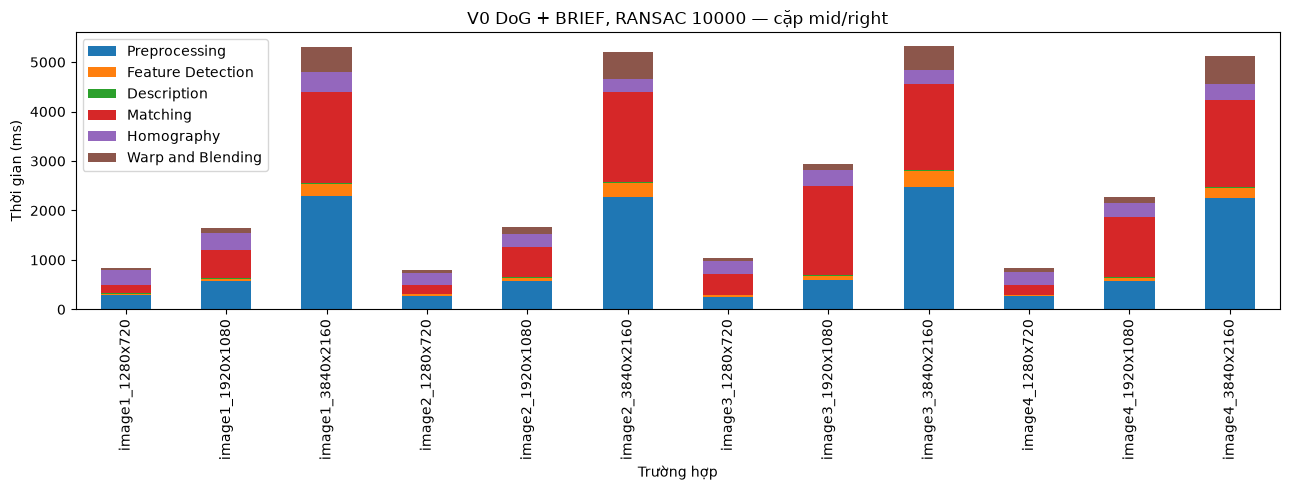

In [12]:
if not timing.empty:
    stage_times = timing.set_index("Trường hợp")[[f"Bước {i} (ms)" for i in range(1, 7)]]
    stage_times.columns = stage_names
    stage_times.plot.bar(stacked=True, figsize=(13, 5))
    plt.ylabel("Thời gian (ms)")
    plt.title("V0 DoG + BRIEF, RANSAC 10000 — cặp mid/right")
    plt.tight_layout()
    plt.savefig(out / "stage_times.png", dpi=150)
    plt.show()

## Panorama của tất cả trường hợp

Các hình xem trước dưới đây được thu nhỏ để hiển thị. Ảnh PNG đầy đủ của mỗi trường hợp được lưu trong `outputs/mid_right/`. Việc xuất được ảnh và số inlier cao chưa đủ để khẳng định căn chỉnh hoàn toàn chính xác; cần xem thêm vùng chồng lấp và hiện tượng bóng đôi.

In [13]:
def show_panoramas(size):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    fig.subplots_adjust(left=0.02, right=0.98, top=0.94, bottom=0.02, hspace=0.17, wspace=0.06)
    for group, axis in enumerate(axes.ravel(), 1):
        name = f"image{group}_{size}"
        status = (out / f"{name}.status").read_text(encoding="utf-8").strip()
        if status == "ok":
            with Image.open(out / f"{name}.png") as image:
                image.thumbnail((1600, 1000))
                axis.imshow(image)
        else:
            axis.text(0.5, 0.5, "Không xuất được panorama", ha="center")
        axis.set_title(f"Bộ {group}, {size} — mid/right")
        axis.axis("off")
    fig.savefig(out / f"panoramas_{size}.png", dpi=130, bbox_inches="tight")
    plt.show()

### Kết quả 1280x720

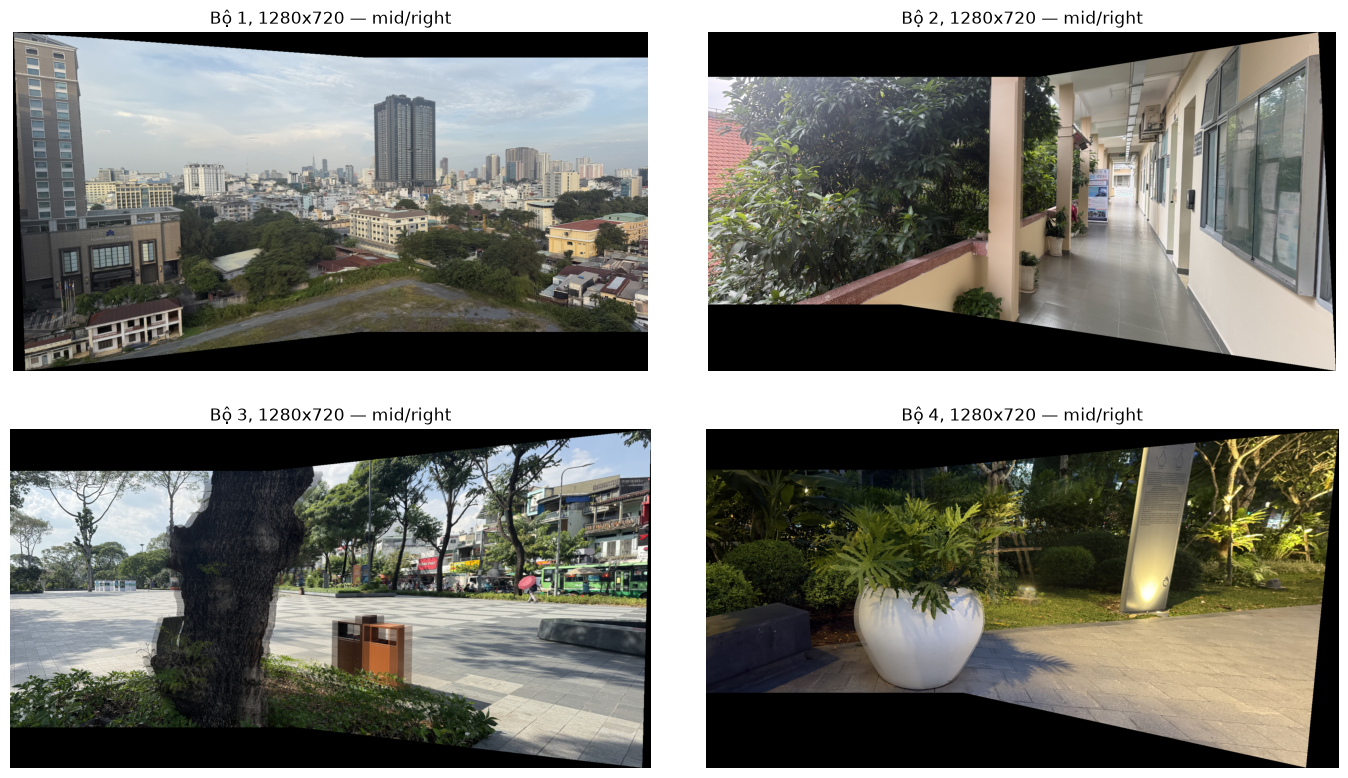

In [14]:
show_panoramas("1280x720")

### Kết quả 1920x1080

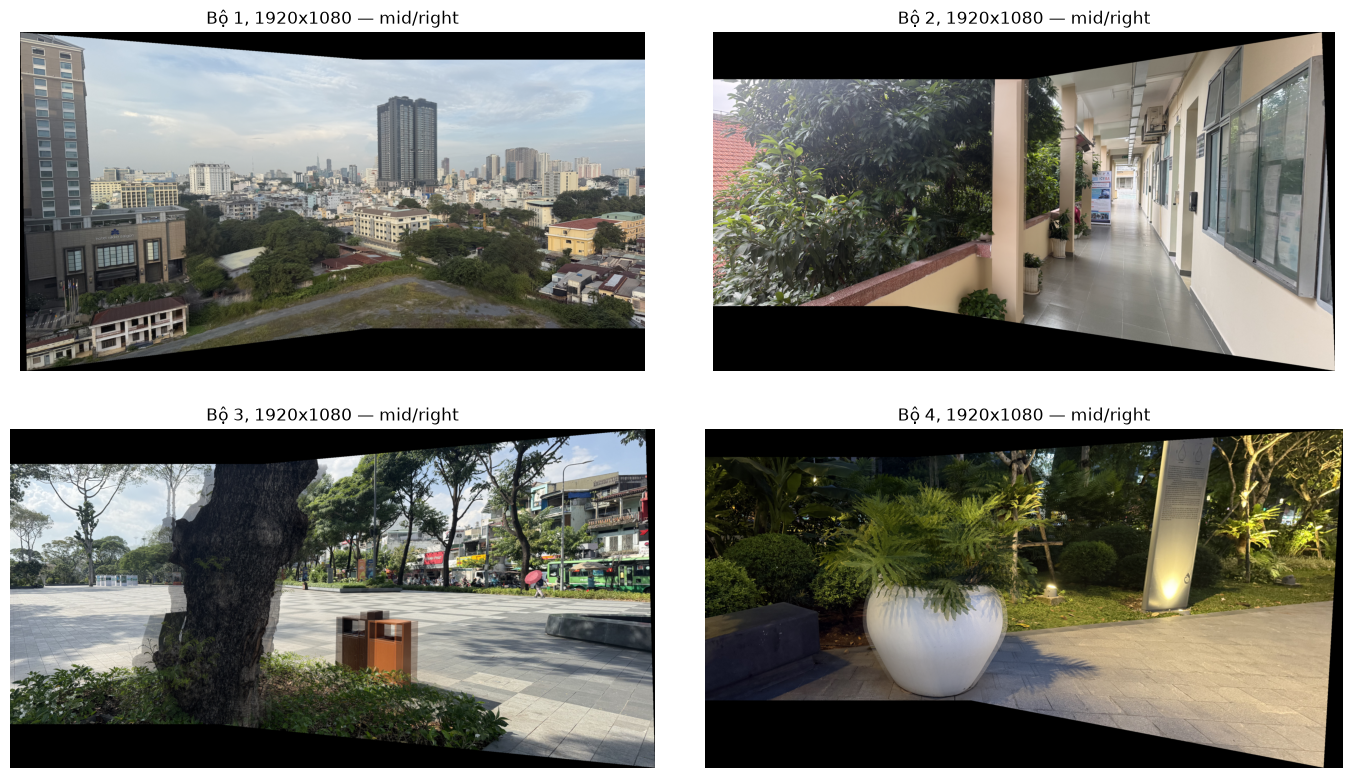

In [15]:
show_panoramas("1920x1080")

### Kết quả 3840x2160

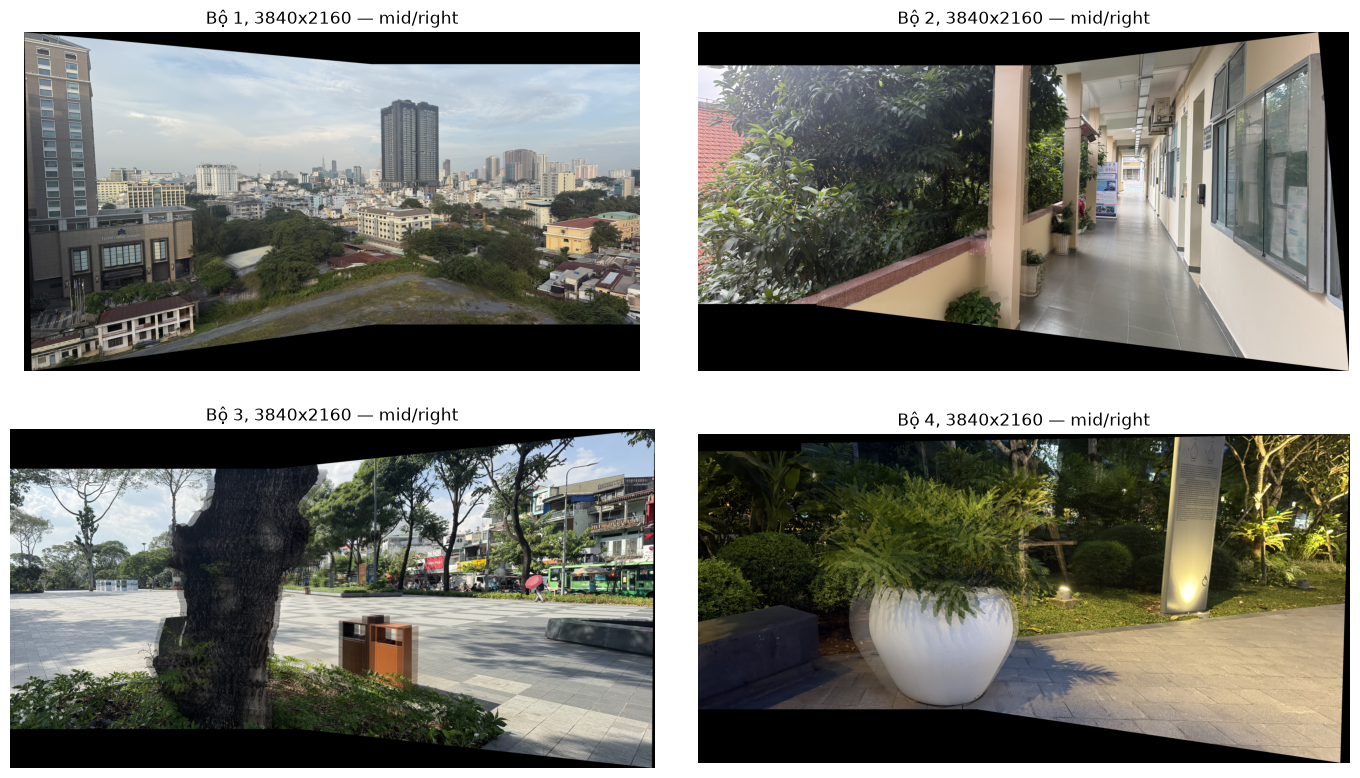

In [16]:
show_panoramas("3840x2160")

# Dataset

Benchmark sử dụng **24 ảnh**, tương ứng bốn cặp `mid/right` ở ba độ phân giải, tạo thành 12 trường hợp thử:

| Bộ ảnh | Ảnh A | Ảnh B | Các kích thước |
|---|---|---|---|
| 1 | `image1_mid_SIZE.jpg` | `image1_right_SIZE.jpg` | 1280×720, 1920×1080, 3840×2160 |
| 2 | `image2_mid_SIZE.jpg` | `image2_right_SIZE.jpg` | 1280×720, 1920×1080, 3840×2160 |
| 3 | `image3_mid_SIZE.jpg` | `image3_right_SIZE.jpg` | 1280×720, 1920×1080, 3840×2160 |
| 4 | `image4_mid_SIZE.jpg` | `image4_right_SIZE.jpg` | 1280×720, 1920×1080, 3840×2160 |

Trong đó `SIZE` lần lượt là `1280x720`, `1920x1080`, `3840x2160`. Ảnh mid được chọn làm hệ tọa độ tham chiếu A. Danh sách tệp đầu vào, mã SHA-256 và trạng thái từng trường hợp nằm trong `outputs/mid_right/manifest.json`.

# GPU plan

## Mục tiêu

V1 chuyển sáu stage của pipeline ghép ảnh từ V0 tuần tự trên CPU sang CUDA. Mục tiêu là khai thác tính song song của các phép tính theo pixel, keypoint, cặp descriptor, giả thuyết RANSAC và pixel đầu ra.

V0 được dùng làm mốc so sánh. V1 trước hết cần cho kết quả hình học và panorama tương đương V0; sau đó nhóm mới đánh giá thời gian thực thi. V2 và V3 sẽ bổ sung tối ưu dựa trên kết quả profiling, mỗi phiên bản tập trung vào một thay đổi chính để có thể đo riêng tác động.

## Phân chia công việc trên GPU

| Stage | Công việc trên GPU | Cách tổ chức song song dự kiến |
|---|---|---|
| **1. Preprocessing** | Chuyển RGB sang ảnh xám; tính các mức Gaussian bằng lọc separable. | Mỗi luồng xử lý một pixel đầu ra. Lượt lọc ngang và dọc chạy lần lượt vì lượt dọc cần kết quả của lượt ngang. Các pixel trong cùng một lượt được tính độc lập. |
| **2. Keypoint detection** | Tính Difference of Gaussians (DoG), kiểm tra cực trị trong lân cận $3\times3\times3$, ngưỡng tương phản và điều kiện Hessian. | Mỗi luồng kiểm tra một vị trí ứng viên. Các ứng viên hợp lệ được ghi vào vùng đệm riêng; sau đó cần bước thu gom và chọn tối đa 4000 điểm theo response. Cần xử lý trường hợp số ứng viên vượt sức chứa vùng đệm. |
| **3. Description** | Tính descriptor BRIEF 256 bit cho mỗi keypoint bằng 256 phép so sánh cường độ. | Mỗi luồng hoặc nhóm luồng xử lý một keypoint. Mẫu lấy điểm cố định trong `brief_pattern.h` được dùng chung trên GPU. Cần giữ cùng quy tắc bỏ keypoint quá gần biên như V0. |
| **4. Matching** | Tính khoảng cách Hamming giữa descriptor của A và B, tìm hai ứng viên gần nhất và áp dụng ratio test 0.8. | Chia công việc theo descriptor của A và các descriptor của B. Mỗi descriptor A cần tìm top hai khoảng cách nhỏ nhất trong B. Kết quả ghép được giữ cùng quy tắc một chiều từ A sang B như V0. |
| **5. Homography estimation** | Chạy các giả thuyết RANSAC, ước lượng homography từ bốn cặp điểm, rồi đếm inlier theo ngưỡng chiếu lại 3 pixel. | Các giả thuyết RANSAC độc lập nên có thể được đánh giá song song theo lô. Mỗi giả thuyết cần đánh giá trên danh sách match; sau đó giảm kết quả để chọn mô hình có nhiều inlier nhất, dùng tổng sai số làm tiêu chí phụ. Cuối cùng fit lại homography bằng toàn bộ inlier tốt nhất. |
| **6. Warping and blending** | Tính vị trí lấy mẫu trong ảnh B cho mỗi pixel trên canvas, nội suy song tuyến tính và feather blending với ảnh A. | Mỗi luồng xử lý một pixel đầu ra. Phép biến đổi ngược dùng $H^{-1}$, nhờ đó tránh nhiều luồng cùng ghi vào một pixel. Cần kiểm tra biên ảnh và giữ quy tắc pixel đen vẫn là dữ liệu hợp lệ nếu tọa độ nằm trong ảnh. |

## Luồng dữ liệu

Ảnh đầu vào được đọc và giải mã trên CPU, sau đó dữ liệu được chép lên GPU. Các stage từ preprocessing đến homography trao đổi dữ liệu qua bộ nhớ GPU khi có thể, hạn chế chép trung gian về CPU. Kết quả cần cho bước kế tiếp, chẳng hạn ảnh xám, Gaussian, keypoint, descriptor và match, được giữ trên GPU trong suốt pipeline. Sau khi hoàn tất warp và blending, panorama được chép về CPU để lưu tệp.

## Kế hoạch các phiên bản

- **V0 - CPU tuần tự:** phiên bản hiện có, làm mốc về thời gian, số lượng đặc trưng, homography, sai số inlier và ảnh panorama.
- **V1 - CUDA cơ bản:** chuyển các phép tính của sáu stage lên GPU theo cách trực tiếp, ưu tiên tính đúng và khả năng đối chiếu với V0. Chưa áp dụng tối ưu sâu trước khi đo baseline.
- **V2 - Bản tối ưu đầu tiên:** dùng profiling V1 để chọn stage chiếm nhiều thời gian nhất. Nhóm sẽ chọn một thay đổi chính, triển khai và so sánh với V1.
- **V3 - Bản tối ưu tiếp theo:** giữ lại các tối ưu có lợi từ V2, sau đó thử thêm một thay đổi chính khác. Chỉ giữ thay đổi nếu cải thiện thời gian mà vẫn đáp ứng tiêu chí chất lượng.

Các hướng có thể được cân nhắc sau khi profiling gồm giảm truyền dữ liệu giữa CPU và GPU, dùng bộ nhớ dùng chung hoặc truy cập bộ nhớ hợp nhất phù hợp với kernel, xử lý nhiều giả thuyết RANSAC theo lô, và tối ưu bước thu gom/top-K keypoint. Đây là các phương án cần được đo trước khi quyết định áp dụng.

## Kiểm tra tính chính xác và đo hiệu năng

Tất cả phiên bản cần dùng cùng 12 trường hợp `mid/right` trong bộ dữ liệu, cùng thứ tự ảnh, cùng các tham số thuật toán: tối đa 4000 keypoint, BRIEF 256 bit, ratio test 0.8, 10000 vòng RANSAC và ngưỡng inlier 3 pixel. Dùng seed cố định khi lấy mẫu RANSAC để hỗ trợ tái lập; nếu việc song song hóa làm thứ tự xử lý thay đổi, cần ghi rõ cách xử lý tie-break và kiểm tra độ ổn định kết quả.

Với mỗi trường hợp sẽ cần kiểm tra:

- Thời gian trung bình và độ lệch chuẩn của từng stage và toàn pipeline.
- Thời gian kernel và thời gian truyền dữ liệu riêng khi có thể đo được.
- Số keypoint của hai ảnh, số match, số inlier, tỷ lệ inlier và sai số inlier.
- Tốc độ tăng tốc so với V0, tính bằng:
  $$
  \text{Speedup}=\frac{T_{\mathrm{V0}}}{T_{\mathrm{GPU}}}.
  $$
- Ảnh panorama đầu ra để kiểm tra trực quan hiện tượng lệch ảnh, đường nối hoặc mất vùng.

## Tiêu chí chấp nhận

Một phiên bản GPU được xem là đạt yêu cầu khi:

1. Chạy thành công trên cùng các trường hợp benchmark như V0.
2. Các số liệu hình học như số match, số inlier và sai số chiếu lại không suy giảm đáng kể; khác biệt do thứ tự tính toán song song cần được ghi nhận.
3. Panorama giữ được nội dung và vùng chồng lấp tương đương V0 khi so sánh trực quan.
4. Thời gian được đo sẽ bao gồm chi phí truyền dữ liệu cần thiết cho pipeline.